## Nama: Gracia Aurelya Krisma
## NIM: H061241066
## Kelas: C

In [1]:
# ============ SETUP (jalankan sekali di awal) ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy.ndimage import gaussian_filter
from IPython.display import display

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# CATATAN: semua data di bawah ini adalah DATA DEMO (sintetik) hanya untuk
# menghasilkan gambar & tabel contoh. Bukan data lapangan.


## 1. Studi Kasus Ground Penetrating Radar (GPR)

### **Role:**

Anda adalah seorang geofisikawan yang memiliki pengalaman dalam metode Ground Penetrating Radar (GPR), khususnya dalam pengolahan dan interpretasi radargram untuk mengetahui kondisi bawah permukaan dangkal.

### **Task:**

Analisis data GPR untuk mengidentifikasi pola refleksi, batas lapisan bawah permukaan, serta anomali yang kemungkinan menunjukkan keberadaan objek atau struktur tertentu di bawah permukaan. Jelaskan dasar geofisika dari setiap hasil interpretasi yang diperoleh.

### **Context:**

Survei GPR dilakukan untuk mengetahui kondisi bawah permukaan pada suatu wilayah. Data GPR ditampilkan dalam bentuk radargram yang memperlihatkan variasi amplitudo refleksi terhadap posisi lintasan dan waktu tempuh gelombang. Hasil analisis akan digunakan untuk memberikan gambaran awal mengenai struktur bawah permukaan.

### **Input:**

Data yang diberikan berupa radargram GPR, frekuensi antena, panjang lintasan, posisi pengukuran, serta informasi mengenai kondisi geologi atau keadaan lokasi apabila tersedia.

### **Constraints:**

* Jangan membuat atau menambahkan nilai data yang tidak diberikan.
* Jangan menyatakan jenis material atau objek secara pasti apabila data belum cukup mendukung.
* Bedakan antara hasil pengamatan pada radargram dan hasil interpretasi.
* Gunakan konsep dasar GPR dalam menjelaskan setiap anomali.
* Jika terdapat informasi yang tidak tersedia, jelaskan keterbatasannya.

### **Output:**

Buat narasi interpretasi yang menjelaskan kondisi umum radargram, pola refleksi yang terlihat, lokasi atau zona anomali, kemungkinan penyebab anomali, serta keterbatasan interpretasi. Hasil akhir disajikan dalam bentuk narasi dan tabel sederhana, bukan gambar.

### **Quality Criteria:**

Interpretasi harus sesuai dengan prinsip dasar metode GPR, memiliki alasan geofisika yang jelas, tidak memberikan kesimpulan yang melebihi data, serta membedakan fakta hasil pengamatan dengan dugaan interpretasi.

### **Optional Verification:**

Apabila tersedia, bandingkan hasil interpretasi GPR dengan informasi geologi, data bor, atau hasil pengukuran lapangan lainnya untuk mengetahui apakah interpretasi tersebut sesuai dengan kondisi sebenarnya.

### Kode & Hasil (data demo)

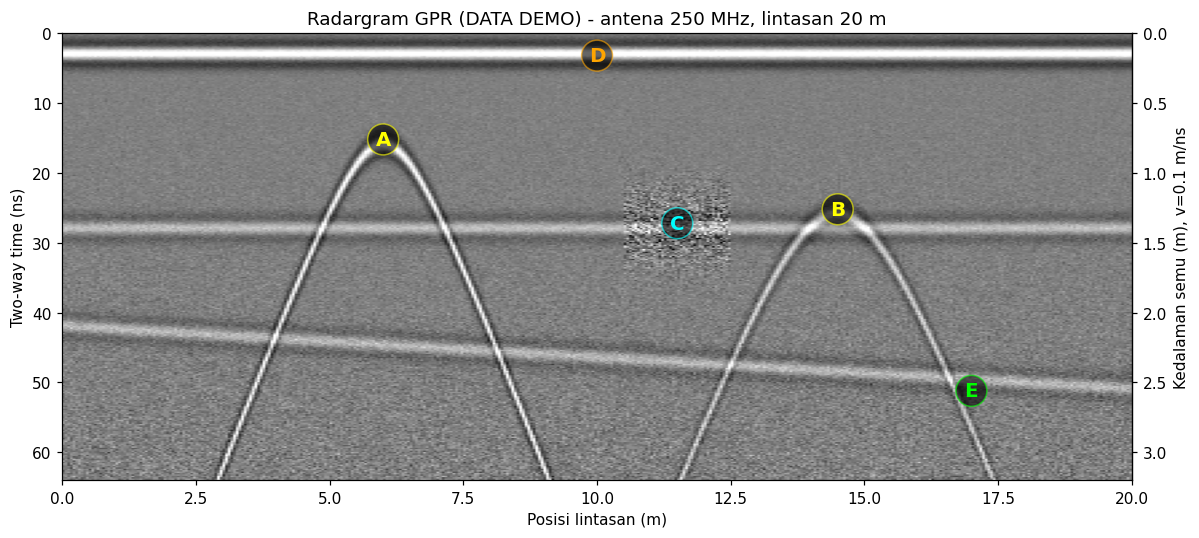

,Zona,Posisi,Waktu tempuh,Pengamatan (fakta radargram),Interpretasi (dugaan),Keterbatasan
0,A,x ≈ 6 m,apeks ≈ 16 ns,"Pola hiperbola, amplitudo kuat","Dugaan objek kecil/lokal dengan kontras permitivitas (mis. pipa, rongga, batu). Jenis belum dapat dipastikan.",Satu profil saja; orientasi objek tidak diketahui.
1,B,x ≈ 14.5 m,apeks ≈ 26 ns,Hiperbola lebih lemah/lebih dalam,Dugaan objek lain yang lebih dalam atau kontras lebih kecil.,Kecepatan v diasumsikan konstan; kedalaman hanya perkiraan.
2,C,x ≈ 10.5–12.5 m,≈ 28 ns,Refleksi horizontal terputus/tidak koheren,"Dugaan gangguan lapisan (heterogenitas, zona tidak menerus, atau noise lokal).",Tidak ada data bor untuk memastikan.
3,D,seluruh lintasan,≈ 3 ns,Gelombang langsung kuat dan menerus,Antarmuka udara–tanah/gelombang langsung antena.,Menutupi refleksi dangkal (blind zone).
4,E,seluruh lintasan,42 → 51 ns (miring),Refleksi miring menerus,Dugaan batas lapisan yang miring ke arah lintasan bertambah (ke kanan).,"Kemiringan semu, bergantung arah lintasan."


In [2]:
# ============ 1. GPR - Radargram demo ============
np.random.seed(1)
f_ant = 250e6                 # frekuensi antena demo (Hz)
L = 20.0                      # panjang lintasan demo (m)
v = 0.10                      # kecepatan gelombang demo (m/ns), asumsi tunggal
nx, nt = 400, 320
x = np.linspace(0, L, nx)
t = np.linspace(0, 64, nt)    # two-way time (ns)

def ricker(t, t0, f=f_ant/1e9):
    a = (np.pi * f * (t - t0))**2
    return (1 - 2*a) * np.exp(-a)

rad = np.zeros((nt, nx))
for i, xi in enumerate(x):
    tr = 1.0 * ricker(t, 3.0)                                  # gelombang langsung
    tr += 0.45 * ricker(t, 28.0)                               # reflektor horizontal
    tr += 0.40 * ricker(t, 42.0 + 0.45 * xi)                   # reflektor miring
    for x0, d, A in [(6.0, 0.8, 0.9), (14.5, 1.3, 0.6)]:       # hiperbola difraksi
        tr += A * ricker(t, (2/v) * np.sqrt(d**2 + (xi - x0)**2))
    if 10.5 < xi < 12.5:                                       # zona gangguan reflektor
        tr += 0.35 * np.random.randn(nt) * np.exp(-((t-28)/6)**2)
    rad[:, i] = tr * np.exp(-t / 40.0)                         # atenuasi
rad += 0.03 * np.random.randn(nt, nx)                          # noise
rad *= np.exp(t / 40.0)[:, None] * 0.9                         # gain kompensasi

fig, ax = plt.subplots(figsize=(11, 5))
vmax = np.percentile(np.abs(rad), 99)
ax.imshow(rad, cmap="gray", aspect="auto", vmin=-vmax, vmax=vmax,
          extent=[0, L, t[-1], 0])
ax.set_xlabel("Posisi lintasan (m)"); ax.set_ylabel("Two-way time (ns)")
ax.set_title(f"Radargram GPR (DATA DEMO) - antena {f_ant/1e6:.0f} MHz, lintasan {L:.0f} m")
sec = ax.secondary_yaxis("right", functions=(lambda tt: v*tt/2, lambda d: 2*d/v))
sec.set_ylabel(f"Kedalaman semu (m), v={v} m/ns")
for (xa, ta, lab, c) in [(6, 16, "A", "yellow"), (14.5, 26, "B", "yellow"),
                         (11.5, 28, "C", "cyan"), (10, 4, "D", "orange"),
                         (17, 52, "E", "lime")]:
    ax.annotate(lab, (xa, ta), color=c, fontsize=13, fontweight="bold",
                ha="center", bbox=dict(boxstyle="circle", fc="black", ec=c, alpha=.6))
plt.tight_layout(); plt.show()

tabel_gpr = pd.DataFrame([
    ["A", "x ≈ 6 m", "apeks ≈ 16 ns", "Pola hiperbola, amplitudo kuat",
     "Dugaan objek kecil/lokal dengan kontras permitivitas (mis. pipa, rongga, batu). Jenis belum dapat dipastikan.",
     "Satu profil saja; orientasi objek tidak diketahui."],
    ["B", "x ≈ 14.5 m", "apeks ≈ 26 ns", "Hiperbola lebih lemah/lebih dalam",
     "Dugaan objek lain yang lebih dalam atau kontras lebih kecil.",
     "Kecepatan v diasumsikan konstan; kedalaman hanya perkiraan."],
    ["C", "x ≈ 10.5–12.5 m", "≈ 28 ns", "Refleksi horizontal terputus/tidak koheren",
     "Dugaan gangguan lapisan (heterogenitas, zona tidak menerus, atau noise lokal).",
     "Tidak ada data bor untuk memastikan."],
    ["D", "seluruh lintasan", "≈ 3 ns", "Gelombang langsung kuat dan menerus",
     "Antarmuka udara–tanah/gelombang langsung antena.",
     "Menutupi refleksi dangkal (blind zone)."],
    ["E", "seluruh lintasan", "42 → 51 ns (miring)", "Refleksi miring menerus",
     "Dugaan batas lapisan yang miring ke arah lintasan bertambah (ke kanan).",
     "Kemiringan semu, bergantung arah lintasan."],
], columns=["Zona", "Posisi", "Waktu tempuh", "Pengamatan (fakta radargram)",
            "Interpretasi (dugaan)", "Keterbatasan"])
display(tabel_gpr)


# 2. Studi Kasus Geolistrik Resistivitas

### **Role:**

Anda adalah seorang geofisikawan yang memiliki pengalaman dalam metode geolistrik resistivitas, khususnya dalam menganalisis variasi resistivitas untuk mengetahui kondisi bawah permukaan.

### **Task:**

Analisis data resistivitas untuk mengidentifikasi perbedaan lapisan bawah permukaan, zona dengan karakteristik resistivitas yang berbeda, serta kemungkinan keberadaan material atau zona jenuh air.

### **Context:**

Survei geolistrik dilakukan untuk memperoleh informasi mengenai kondisi bawah permukaan suatu wilayah. Perbedaan nilai resistivitas dapat menunjukkan adanya perbedaan sifat fisik material bawah permukaan. Namun, satu nilai resistivitas dapat memiliki lebih dari satu kemungkinan interpretasi sehingga hasil harus dijelaskan secara hati-hati.

### **Input:**

Data yang diberikan berupa nilai resistivitas, hasil inversi apabila tersedia, konfigurasi elektroda, posisi titik pengukuran, kedalaman investigasi, serta informasi geologi daerah penelitian.

### **Constraints:**

* Jangan menentukan jenis batuan secara mutlak hanya berdasarkan nilai resistivitas.
* Jangan membuat nilai resistivitas atau kedalaman yang tidak terdapat pada data.
* Jelaskan asumsi yang digunakan dalam interpretasi.
* Bedakan hasil pengukuran atau inversi dengan interpretasi geologi.
* Sebutkan keterbatasan apabila kualitas atau informasi data tidak mencukupi.

### **Output:**

Buat narasi yang menjelaskan variasi nilai resistivitas, pembagian zona atau lapisan, kemungkinan material penyusun, serta indikasi zona yang berpotensi mengandung air tanah apabila didukung oleh data. Sajikan hasil dalam narasi dan tabel yang berisi zona, karakteristik resistivitas, kemungkinan material, dan alasan interpretasinya.

### **Quality Criteria:**

Hasil interpretasi harus sesuai dengan prinsip dasar metode geolistrik resistivitas, mempertimbangkan kemungkinan ambiguitas, memberikan alasan yang jelas, dan tidak menyimpulkan jenis material secara berlebihan.

### **Optional Verification:**

Bandingkan hasil interpretasi dengan data geologi, data sumur, singkapan batuan, atau informasi hidrogeologi apabila tersedia.

### Kode & Hasil (data demo)

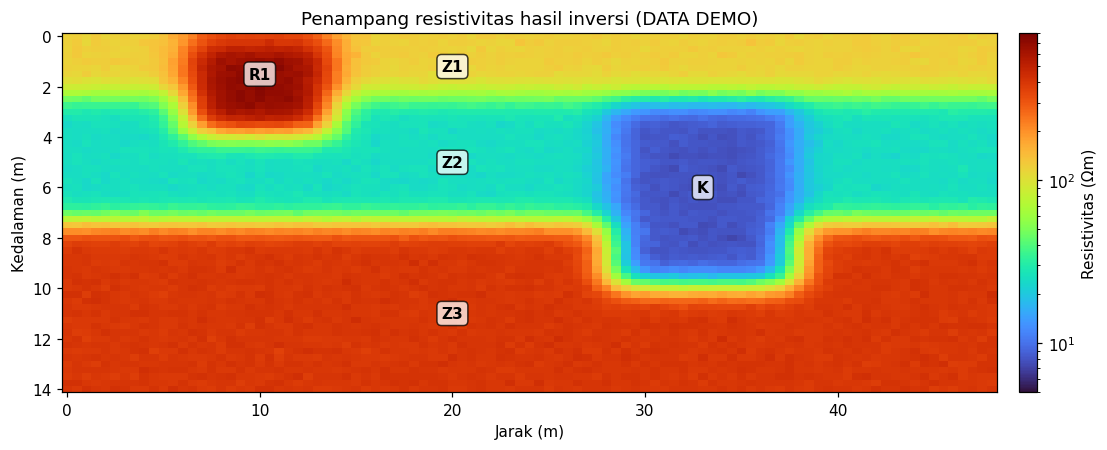

,Zona,Karakteristik resistivitas (dari model),Kemungkinan material (dugaan),Alasan & catatan interpretasi
0,Z1 (lapisan atas),95 – 134 Ωm,Tanah/material lepas kering atau sebagian jenuh,Resistivitas menengah-tinggi karena kandungan air rendah di dekat permukaan.
1,Z2 (lapisan tengah),23 – 28 Ωm,Material halus/lempungan atau material jenuh air (ambigu),Resistivitas rendah dapat berasal dari lempung ATAU air tanah; perlu data sumur.
2,Z3 (lapisan bawah),364 – 433 Ωm,"Material lebih kompak/resistif (batuan lapuk–segar, atau material kering)",Resistivitas tinggi → porositas/kadar air rendah; jenis batuan tidak dapat dipastikan.
3,K (anomali rendah),7 – 9 Ωm,Zona sangat konduktif: kemungkinan jenuh air/air payau atau lempung (ambigu),Konduktivitas tinggi akibat air berion/lempung; tidak dapat dibedakan hanya dari ρ.
4,R1 (anomali tinggi),346 – 756 Ωm,Material sangat resistif dangkal: kering/berongga/fragmen batuan (ambigu),Kontras tinggi lokal; efek smoothing inversi membuat batas tampak gradual.


In [3]:
# ============ 2. Geolistrik Resistivitas - penampang inversi demo ============
np.random.seed(2)
xs = np.linspace(0, 48, 97)          # posisi (m); 25 elektroda, spasi 2 m (demo)
zs = np.linspace(0, 14, 57)          # kedalaman (m)
X, Z = np.meshgrid(xs, zs)

rho = np.full_like(X, 120.0)                     # lapisan atas
rho[(Z >= 2.5) & (Z < 7.5)] = 25.0               # lapisan tengah
rho[Z >= 7.5] = 400.0                            # lapisan bawah
rho[(X > 28) & (X < 38) & (Z > 2.5) & (Z < 10)] = 8.0       # anomali konduktif
rho[(X > 6) & (X < 14) & (Z > 0) & (Z < 4)] = 700.0         # anomali resistif dangkal
rho = np.exp(gaussian_filter(np.log(rho), sigma=2.0))       # efek smoothing inversi
rho *= np.exp(0.03 * np.random.randn(*rho.shape))

fig, ax = plt.subplots(figsize=(11, 4.2))
pc = ax.pcolormesh(X, Z, rho, cmap="turbo", norm=LogNorm(vmin=5, vmax=800), shading="auto")
ax.invert_yaxis()
cb = plt.colorbar(pc, ax=ax, pad=0.02); cb.set_label("Resistivitas (Ωm)")
ax.set_xlabel("Jarak (m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title("Penampang resistivitas hasil inversi (DATA DEMO)")
for lab, xa, za in [("R1", 10, 1.5), ("Z1", 20, 1.2), ("Z2", 20, 5.0),
                    ("K", 33, 6.0), ("Z3", 20, 11.0)]:
    ax.text(xa, za, lab, ha="center", va="center", fontweight="bold",
            bbox=dict(boxstyle="round", fc="white", alpha=.75))
plt.tight_layout(); plt.show()

def rng(mask):
    return f"{rho[mask].min():.0f} – {rho[mask].max():.0f} Ωm"

zona = {
    "Z1 (lapisan atas)":   (Z < 2.0) & (X > 15) & (X < 26),
    "Z2 (lapisan tengah)": (Z > 3.5) & (Z < 6.5) & (X > 15) & (X < 26),
    "Z3 (lapisan bawah)":  (Z > 9.5) & (X > 15) & (X < 26),
    "K (anomali rendah)":  (X > 30) & (X < 36) & (Z > 4) & (Z < 8),
    "R1 (anomali tinggi)": (X > 8) & (X < 12) & (Z < 2.5),
}
tabel_res = pd.DataFrame({
    "Zona": list(zona.keys()),
    "Karakteristik resistivitas (dari model)": [rng(m) for m in zona.values()],
    "Kemungkinan material (dugaan)": [
        "Tanah/material lepas kering atau sebagian jenuh",
        "Material halus/lempungan atau material jenuh air (ambigu)",
        "Material lebih kompak/resistif (batuan lapuk–segar, atau material kering)",
        "Zona sangat konduktif: kemungkinan jenuh air/air payau atau lempung (ambigu)",
        "Material sangat resistif dangkal: kering/berongga/fragmen batuan (ambigu)"],
    "Alasan & catatan interpretasi": [
        "Resistivitas menengah-tinggi karena kandungan air rendah di dekat permukaan.",
        "Resistivitas rendah dapat berasal dari lempung ATAU air tanah; perlu data sumur.",
        "Resistivitas tinggi → porositas/kadar air rendah; jenis batuan tidak dapat dipastikan.",
        "Konduktivitas tinggi akibat air berion/lempung; tidak dapat dibedakan hanya dari ρ.",
        "Kontras tinggi lokal; efek smoothing inversi membuat batas tampak gradual."],
})
display(tabel_res)


# 3. Studi Kasus Seismik Refraksi

### **Role:**

Anda adalah seorang geofisikawan yang berpengalaman dalam metode seismik refraksi, khususnya dalam analisis waktu tiba gelombang untuk menentukan struktur dan kecepatan lapisan bawah permukaan.

### **Task:**

Analisis data seismik refraksi untuk menentukan jumlah lapisan bawah permukaan, memperkirakan kecepatan gelombang pada setiap lapisan, serta memberikan interpretasi mengenai kondisi geologi bawah permukaan.

### **Context:**

Survei seismik refraksi dilakukan dengan menempatkan beberapa geofon pada sepanjang lintasan pengukuran. Gelombang seismik diberikan menggunakan sumber tertentu, kemudian waktu tiba gelombang yang direkam oleh geofon digunakan untuk mengetahui variasi kecepatan bawah permukaan.

### **Input:**

Data yang diberikan berupa jarak antar-geofon, waktu tiba gelombang, posisi sumber, data kurva waktu-tempuh, serta informasi topografi dan geologi apabila tersedia.

### **Constraints:**

* Jangan membuat nilai kecepatan atau kedalaman yang tidak diperoleh dari data.
* Jelaskan asumsi yang digunakan dalam menentukan model bawah permukaan.
* Bedakan hasil perhitungan dengan interpretasi geologi.
* Perhatikan kemungkinan adanya lapisan dengan kecepatan rendah.
* Jelaskan ketidakpastian apabila model yang diperoleh memiliki keterbatasan.

### **Output:**

Buat narasi yang menjelaskan pola kurva waktu-tempuh, pembagian lapisan berdasarkan perubahan kemiringan kurva, kecepatan masing-masing lapisan apabila dapat ditentukan, serta kemungkinan kondisi bawah permukaan. Sajikan hasil dalam narasi dan tabel yang memuat lapisan, kecepatan, kedalaman atau ketebalan, dan interpretasi.

### **Quality Criteria:**

Interpretasi harus mengikuti prinsip dasar seismik refraksi, menunjukkan hubungan antara waktu tempuh dan kecepatan gelombang, menjelaskan asumsi yang digunakan, serta menyertakan keterbatasan hasil.

### **Optional Verification:**

Jika tersedia, bandingkan model hasil interpretasi dengan data bor, singkapan batuan, atau informasi geologi daerah penelitian untuk mengetahui kesesuaiannya.

### Kode & Hasil (data demo)

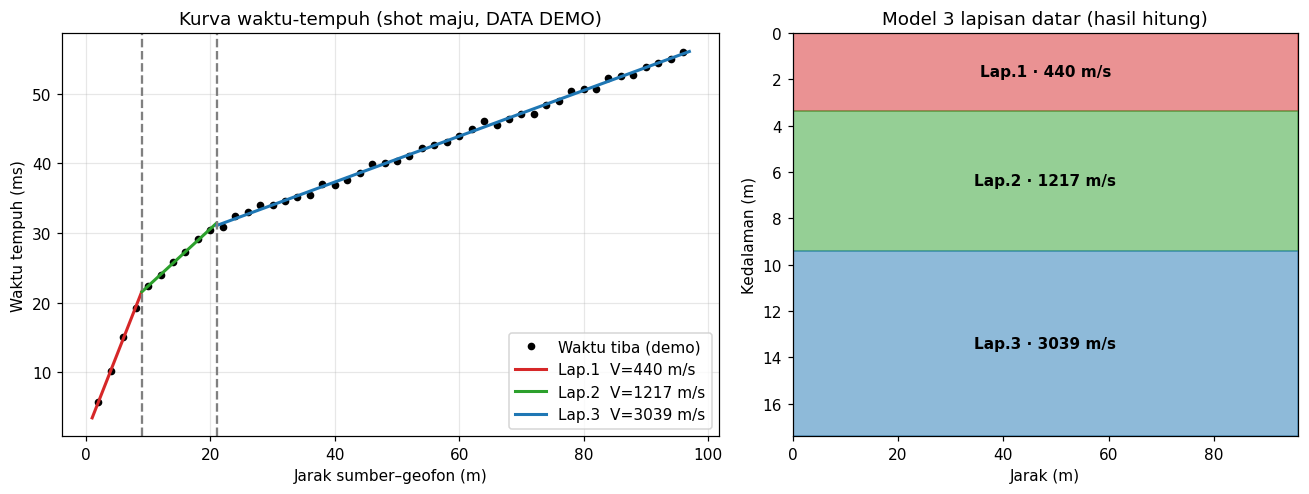

Titik patah (crossover): xc1 ≈ 9.0 m, xc2 ≈ 21.0 m | ti2 = 14.2 ms, ti3 = 24.2 ms


,Lapisan,Kecepatan (m/s),Ketebalan / kedalaman (m),Interpretasi (dugaan),Asumsi & keterbatasan
0,1,440,h1 ≈ 3.3,"Tanah penutup / material lepas, kering","Lapisan datar, homogen, V naik terhadap kedalaman"
1,2,1217,h2 ≈ 6.1 (dasar ≈ 9.4),Material lebih padat / lapuk / mungkin jenuh air,Hanya satu arah tembak; kemiringan tidak teruji; lapisan tersembunyi (hidden layer) / low-velocity layer tidak terdeteksi
2,3 (half-space),3039,tidak terdefinisi,Material kompak (mis. batuan dasar lapuk–segar),Kecepatan tidak menentukan jenis batuan secara pasti


In [4]:
# ============ 3. Seismik Refraksi - kurva waktu-tempuh demo ============
np.random.seed(3)
n, dx = 48, 2.0
x = np.arange(1, n + 1) * dx                  # jarak geofon dari sumber (m)
V1, V2, V3 = 400., 1200., 3000.               # model "benar" demo (m/s)
h1, h2 = 3.0, 6.0                              # ketebalan demo (m)
ti2 = 2*h1*np.cos(np.arcsin(V1/V2))/V1
ti3 = 2*h1*np.cos(np.arcsin(V1/V3))/V1 + 2*h2*np.cos(np.arcsin(V2/V3))/V2
t_obs = np.minimum.reduce([x/V1, x/V2 + ti2, x/V3 + ti3]) + np.random.normal(0, 4e-4, n)

# --- cari 2 titik patah kurva (3 segmen linear) dengan SSE minimum
def sse(i, j):
    xx, tt = x[i:j], t_obs[i:j]
    p = np.polyfit(xx, tt, 1)
    return np.sum((np.polyval(p, xx) - tt)**2), p
best = (np.inf, None)
for i in range(3, n - 6):
    for j in range(i + 3, n - 2):
        s = sse(0, i)[0] + sse(i, j)[0] + sse(j, n)[0]
        if s < best[0]:
            best = (s, (i, j))
i, j = best[1]
p1, p2, p3 = sse(0, i)[1], sse(i, j)[1], sse(j, n)[1]
v1, v2, v3 = 1/p1[0], 1/p2[0], 1/p3[0]
t2, t3 = p2[1], p3[1]                        # intercept time
H1 = t2 * v1 * v2 / (2*np.sqrt(v2**2 - v1**2))
H2 = (t3 - 2*H1*np.sqrt(v3**2 - v1**2)/(v1*v3)) * v2*v3 / (2*np.sqrt(v3**2 - v2**2))
xc1, xc2 = (x[i-1]+x[i])/2, (x[j-1]+x[j])/2

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
a1.plot(x, t_obs*1000, "ko", ms=4, label="Waktu tiba (demo)")
for (a, b, p, c, lab) in [(0, i, p1, "tab:red", f"Lap.1  V={v1:.0f} m/s"),
                          (i, j, p2, "tab:green", f"Lap.2  V={v2:.0f} m/s"),
                          (j, n, p3, "tab:blue", f"Lap.3  V={v3:.0f} m/s")]:
    xx = np.linspace(x[a] - 1, x[b-1] + 1, 20)
    a1.plot(xx, np.polyval(p, xx)*1000, c=c, lw=2, label=lab)
a1.axvline(xc1, ls="--", c="gray"); a1.axvline(xc2, ls="--", c="gray")
a1.set_xlabel("Jarak sumber–geofon (m)"); a1.set_ylabel("Waktu tempuh (ms)")
a1.set_title("Kurva waktu-tempuh (shot maju, DATA DEMO)"); a1.legend(); a1.grid(alpha=.3)

xm = np.array([0, x[-1]])
a2.fill_between(xm, 0, H1, color="tab:red", alpha=.5)
a2.fill_between(xm, H1, H1 + H2, color="tab:green", alpha=.5)
a2.fill_between(xm, H1 + H2, H1 + H2 + 8, color="tab:blue", alpha=.5)
for yy, lab in [(H1/2, f"Lap.1 · {v1:.0f} m/s"), (H1 + H2/2, f"Lap.2 · {v2:.0f} m/s"),
                (H1 + H2 + 4, f"Lap.3 · {v3:.0f} m/s")]:
    a2.text(x[-1]/2, yy, lab, ha="center", va="center", fontweight="bold")
a2.set_ylim(H1 + H2 + 8, 0); a2.set_xlim(0, x[-1])
a2.set_xlabel("Jarak (m)"); a2.set_ylabel("Kedalaman (m)")
a2.set_title("Model 3 lapisan datar (hasil hitung)")
plt.tight_layout(); plt.show()

tabel_sei = pd.DataFrame({
    "Lapisan": ["1", "2", "3 (half-space)"],
    "Kecepatan (m/s)": [f"{v1:.0f}", f"{v2:.0f}", f"{v3:.0f}"],
    "Ketebalan / kedalaman (m)": [f"h1 ≈ {H1:.1f}", f"h2 ≈ {H2:.1f} (dasar ≈ {H1+H2:.1f})", "tidak terdefinisi"],
    "Interpretasi (dugaan)": ["Tanah penutup / material lepas, kering",
                              "Material lebih padat / lapuk / mungkin jenuh air",
                              "Material kompak (mis. batuan dasar lapuk–segar)"],
    "Asumsi & keterbatasan": ["Lapisan datar, homogen, V naik terhadap kedalaman",
                              "Hanya satu arah tembak; kemiringan tidak teruji; lapisan tersembunyi (hidden layer) / low-velocity layer tidak terdeteksi",
                              "Kecepatan tidak menentukan jenis batuan secara pasti"],
})
print(f"Titik patah (crossover): xc1 ≈ {xc1:.1f} m, xc2 ≈ {xc2:.1f} m | ti2 = {t2*1000:.1f} ms, ti3 = {t3*1000:.1f} ms")
display(tabel_sei)


# 4. Studi Kasus Metode Geomagnetik

### **Role:**

Anda adalah seorang geofisikawan yang berpengalaman dalam metode geomagnetik, khususnya dalam menginterpretasikan anomali medan magnet untuk mengetahui variasi sifat kemagnetan bawah permukaan.

### **Task:**

Analisis data geomagnetik untuk mengidentifikasi pola anomali magnetik, membedakan zona anomali positif dan negatif, serta memberikan interpretasi awal mengenai kemungkinan sumber anomali di bawah permukaan.

### **Context:**

Survei geomagnetik dilakukan untuk mengetahui variasi medan magnet pada suatu wilayah. Perbedaan sifat kemagnetan material bawah permukaan dapat menghasilkan variasi nilai medan magnet yang kemudian terlihat sebagai anomali. Interpretasi harus mempertimbangkan kondisi geologi dan kemungkinan adanya gangguan pada data.

### **Input:**

Data yang diberikan berupa koordinat titik pengukuran, nilai medan magnet atau anomali magnetik, hasil koreksi apabila tersedia, serta informasi geologi regional.

### **Constraints:**

* Jangan menentukan jenis batuan secara pasti hanya berdasarkan nilai anomali magnetik.
* Jangan membuat nilai anomali atau lokasi sumber yang tidak terdapat pada data.
* Bedakan pola yang terlihat pada data dengan hasil interpretasi.
* Pertimbangkan kemungkinan adanya noise atau gangguan pada data.
* Jelaskan keterbatasan interpretasi apabila data pendukung tidak tersedia.

### **Output:**

Buat narasi yang menjelaskan pola spasial anomali magnetik, lokasi zona anomali yang menonjol, kemungkinan penyebab anomali berdasarkan sifat kemagnetan material, serta keterbatasan hasil interpretasi. Sajikan dalam narasi dan tabel yang memuat zona anomali, karakteristik, kemungkinan penyebab, dan dasar interpretasinya.

### **Quality Criteria:**

Interpretasi harus sesuai dengan prinsip dasar geomagnetik, memiliki alasan geofisika yang jelas, membedakan data dan interpretasi, serta tidak memberikan kesimpulan yang lebih pasti daripada yang didukung oleh data.

### **Optional Verification:**

Bandingkan hasil interpretasi dengan peta geologi, data singkapan, atau hasil metode geofisika lainnya apabila tersedia untuk mengetahui apakah sumber anomali yang diinterpretasikan memiliki dukungan data tambahan.

### Kode & Hasil (data demo)

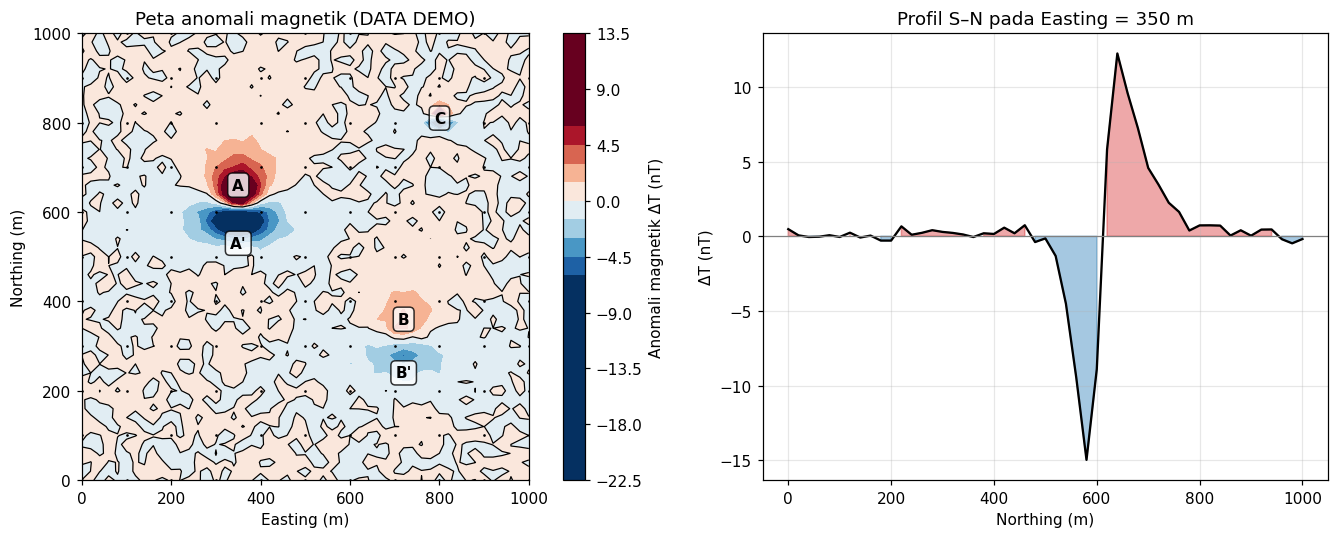

,Zona anomali,Lokasi,Karakteristik (dari data),Kemungkinan penyebab (dugaan),Dasar interpretasi / keterbatasan
0,A (positif),"Utara–barat daya, sisi utara dipol","12.3 nT di (E=340, N=640)",Sumber bersifat magnetik terinduksi (mis. batuan kaya mineral magnetik atau tubuh intrusif) – dugaan,Pasangan positif–negatif khas dipol pada lintang rendah; polaritas tergantung inklinasi.
1,A' (negatif),Sisi selatan zona A,"-15.0 nT di (E=340, N=580)",Lobus negatif dari sumber yang sama (bukan sumber terpisah) – dugaan,"Anomali negatif muncul akibat geometri medan dipol, bukan selalu kemagnetan rendah."
2,B (positif/negatif),Timur–tenggara,"3.2 nT di (E=720, N=340); -4.8 nT di (E=720, N=280)",Sumber kedua yang lebih lemah/lebih dalam – dugaan,Amplitudo lebih kecil & gelombang lebih lebar → kemungkinan lebih dalam.
3,C (spike lokal),"Timur laut (sekitar E=800, N=800)","-21.3 nT di (E=800, N=800)",Objek kecil dangkal atau gangguan antropogenik (logam) – dugaan; bisa juga noise,Panjang gelombang pendek & lokal → sumber sangat dangkal; perlu cek ulang di lapangan.


In [5]:
# ============ 4. Geomagnetik - peta anomali demo ============
np.random.seed(4)
xg = np.arange(0, 1001, 20.0); yg = np.arange(0, 1001, 20.0)
XG, YG = np.meshgrid(xg, yg)
I, D = np.deg2rad(-25.0), np.deg2rad(1.0)                    # inklinasi/deklinasi demo
F = np.array([np.cos(I)*np.sin(D), np.cos(I)*np.cos(D), np.sin(I)])  # (E, N, Down)

def dipole_dT(x0, y0, depth, K):
    """Anomali medan total dipol terinduksi (nT), m sejajar F."""
    dxs, dys, dzs = XG - x0, YG - y0, -depth*np.ones_like(XG)
    r = np.sqrt(dxs**2 + dys**2 + dzs**2)
    cosang = (dxs*F[0] + dys*F[1] + dzs*F[2]) / r
    return K * (3*cosang**2 - 1) / r**3

dT = dipole_dT(350, 600, 60, 4.0e6)          # sumber utama
dT += dipole_dT(720, 300, 80, 2.5e6)         # sumber kedua
dT += dipole_dT(800, 800, 12, 8.0e4)         # sumber dangkal kecil (spike)
dT += 0.3 * np.random.randn(*dT.shape)       # noise

fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})
lim = np.percentile(np.abs(dT), 99)
cs = axs[0].contourf(XG, YG, dT, levels=30, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
axs[0].contour(XG, YG, dT, levels=[0], colors="k", linewidths=.8)
plt.colorbar(cs, ax=axs[0], label="Anomali magnetik ΔT (nT)")
axs[0].plot(XG[::5, ::5], YG[::5, ::5], "k.", ms=1.5)
for lab, xa, ya in [("A", 350, 650), ("A'", 350, 520), ("B", 720, 350), ("B'", 720, 230), ("C", 800, 800)]:
    axs[0].text(xa, ya, lab, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round", fc="white", alpha=.8))
axs[0].set_aspect("equal"); axs[0].set_xlabel("Easting (m)"); axs[0].set_ylabel("Northing (m)")
axs[0].set_title("Peta anomali magnetik (DATA DEMO)")

ix = np.argmin(abs(xg - 350))
axs[1].plot(yg, dT[:, ix], "k-"); axs[1].axhline(0, c="gray", lw=.8)
axs[1].fill_between(yg, 0, dT[:, ix], where=dT[:, ix] > 0, color="tab:red", alpha=.4)
axs[1].fill_between(yg, 0, dT[:, ix], where=dT[:, ix] < 0, color="tab:blue", alpha=.4)
axs[1].set_xlabel("Northing (m)"); axs[1].set_ylabel("ΔT (nT)"); axs[1].grid(alpha=.3)
axs[1].set_title("Profil S–N pada Easting = 350 m")
plt.tight_layout(); plt.show()

def stat(mask, fn):
    v = np.where(mask, dT, np.nan)
    k = np.nanargmax(v) if fn == "max" else np.nanargmin(v)
    return f"{np.ravel(v)[k]:.1f} nT di (E={np.ravel(XG)[k]:.0f}, N={np.ravel(YG)[k]:.0f})"
mA = (XG < 550) & (YG > 400); mB = (XG > 550) & (YG < 500); mC = (abs(XG-800) < 40) & (abs(YG-800) < 40)
tabel_mag = pd.DataFrame([
    ["A (positif)", "Utara–barat daya, sisi utara dipol", stat(mA, "max"),
     "Sumber bersifat magnetik terinduksi (mis. batuan kaya mineral magnetik atau tubuh intrusif) – dugaan",
     "Pasangan positif–negatif khas dipol pada lintang rendah; polaritas tergantung inklinasi."],
    ["A' (negatif)", "Sisi selatan zona A", stat(mA, "min"),
     "Lobus negatif dari sumber yang sama (bukan sumber terpisah) – dugaan",
     "Anomali negatif muncul akibat geometri medan dipol, bukan selalu kemagnetan rendah."],
    ["B (positif/negatif)", "Timur–tenggara", f"{stat(mB, 'max')}; {stat(mB, 'min')}",
     "Sumber kedua yang lebih lemah/lebih dalam – dugaan",
     "Amplitudo lebih kecil & gelombang lebih lebar → kemungkinan lebih dalam."],
    ["C (spike lokal)", "Timur laut (sekitar E=800, N=800)", stat(mC, "min"),
     "Objek kecil dangkal atau gangguan antropogenik (logam) – dugaan; bisa juga noise",
     "Panjang gelombang pendek & lokal → sumber sangat dangkal; perlu cek ulang di lapangan."],
], columns=["Zona anomali", "Lokasi", "Karakteristik (dari data)", "Kemungkinan penyebab (dugaan)", "Dasar interpretasi / keterbatasan"])
display(tabel_mag)


# 5. Studi Kasus Metode Gravitasi

### **Role:**

Anda adalah seorang geofisikawan yang berpengalaman dalam metode gravitasi, khususnya dalam menganalisis anomali gravitasi untuk mengetahui variasi densitas material bawah permukaan.

### **Task:**

Analisis data gravitasi untuk mengidentifikasi pola anomali gravitasi dan memberikan interpretasi awal mengenai kemungkinan variasi densitas material bawah permukaan.

### **Context:**

Survei gravitasi dilakukan untuk mengetahui perubahan medan gravitasi pada suatu wilayah. Perubahan tersebut dapat berkaitan dengan perbedaan densitas material bawah permukaan. Oleh karena itu, interpretasi data gravitasi perlu mempertimbangkan jenis anomali dan koreksi yang telah dilakukan.

### **Input:**

Data yang diberikan berupa koordinat titik pengukuran, nilai gravitasi, nilai anomali Bouguer atau jenis anomali lainnya apabila tersedia, informasi elevasi, koreksi data, serta informasi geologi daerah penelitian.

### **Constraints:**

* Jangan menentukan jenis batuan secara pasti hanya berdasarkan nilai anomali gravitasi.
* Jangan membuat nilai densitas, kedalaman sumber, atau parameter lain yang tidak terdapat pada data.
* Jelaskan jenis anomali yang digunakan dalam analisis.
* Bedakan hasil pengamatan, hasil perhitungan, dan interpretasi geologi.
* Jelaskan keterbatasan dan ambiguitas metode gravitasi.

### **Output:**

Buat narasi yang menjelaskan pola anomali gravitasi, zona dengan nilai relatif tinggi dan rendah, kemungkinan hubungan antara anomali dengan variasi densitas bawah permukaan, serta keterbatasan interpretasi. Sajikan hasil dalam **narasi dan tabel** yang berisi zona anomali, karakteristik, kemungkinan penyebab, dan dasar interpretasinya.

### **Quality Criteria:**

Interpretasi harus sesuai dengan prinsip metode gravitasi, menjelaskan hubungan antara anomali dan densitas secara hati-hati, tidak memberikan kepastian yang tidak didukung data, serta menyebutkan ketidakpastian hasil.

### **Optional Verification:**

Jika tersedia, bandingkan hasil interpretasi dengan data geologi, topografi, data bor, atau hasil metode geofisika lainnya untuk mengetahui apakah interpretasi variasi densitas tersebut didukung oleh informasi tambahan.

### Kode & Hasil (data demo)

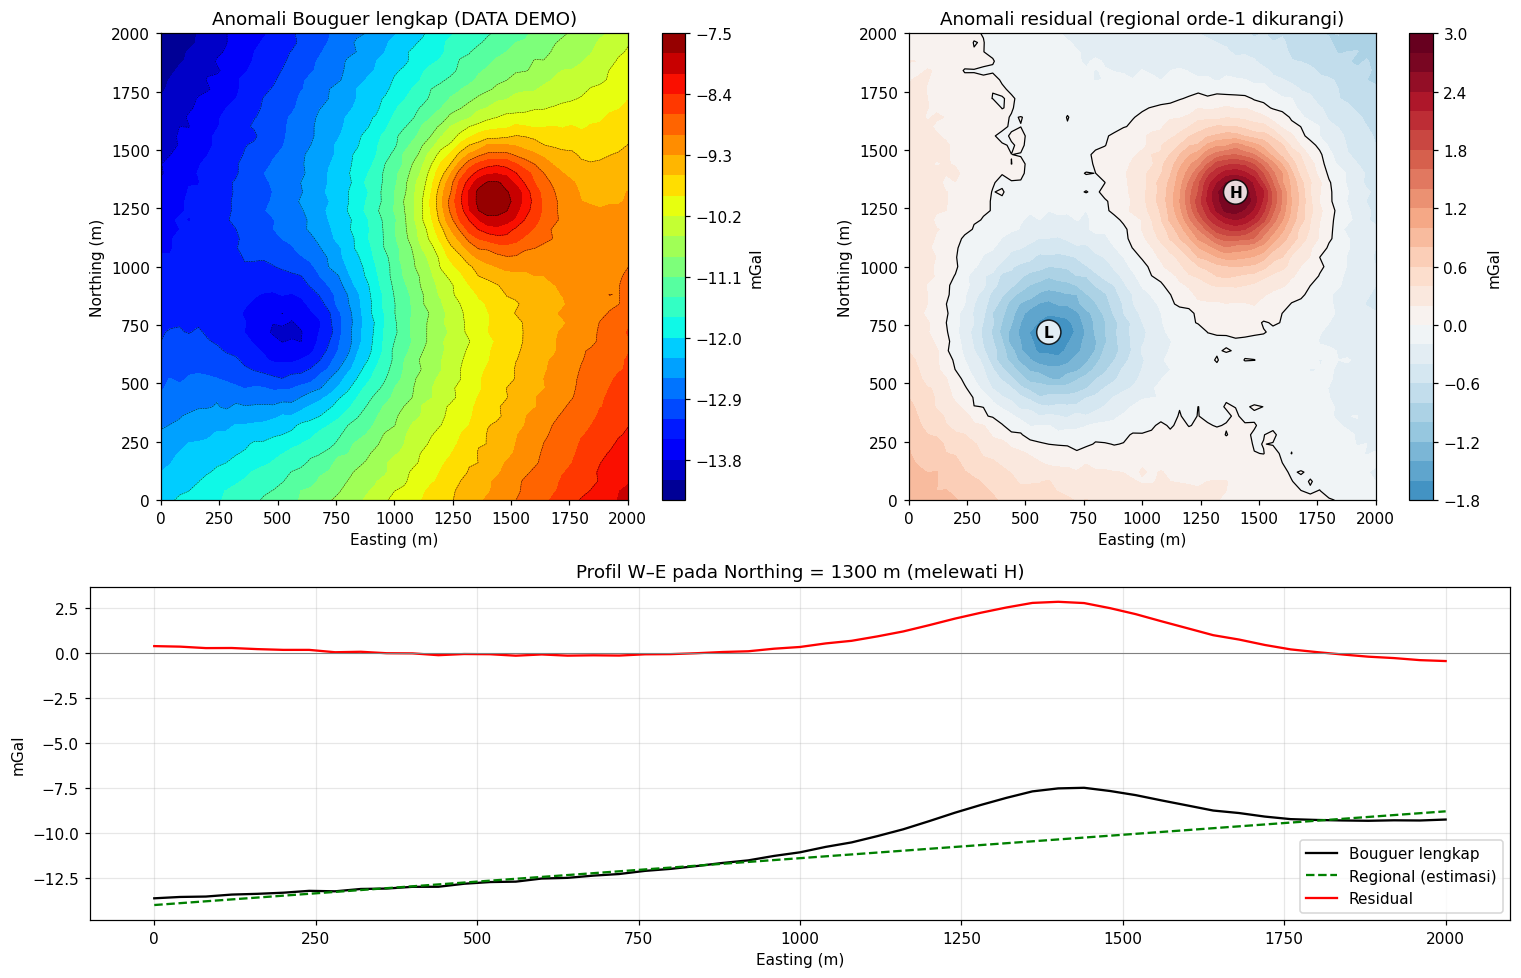

,Zona anomali,Karakteristik (hasil hitung dari data demo),Kemungkinan penyebab (dugaan),Dasar interpretasi / keterbatasan
0,H (residual tinggi),"+2.85 mGal di (E=1400, N=1320)",Material bawah permukaan relatif lebih padat/rapat dari sekitarnya (mis. batuan keras/intrusi) – dugaan,Anomali positif ⇒ kelebihan massa relatif; tidak menentukan jenis batuan.
1,L (residual rendah),"-1.78 mGal di (E=600, N=680)","Material relatif kurang padat (mis. endapan sedimen tebal, zona lapuk/rongga) – dugaan",Anomali negatif ⇒ defisit massa relatif; ambigu terhadap kedalaman & kontras densitas.
2,Tren regional,"gradien ≈ +2.61 mGal/km (E), -0.74 mGal/km (N)",Pengaruh struktur dalam/regional yang luas,Pemisahan orde-1 bersifat sederhana; hasil residual bergantung metode.


Catatan: ambiguitas gravitasi - banyak kombinasi densitas/kedalaman/bentuk yang memberi anomali sama.


In [6]:
# ============ 5. Gravitasi - anomali Bouguer demo ============
np.random.seed(5)
G = 6.674e-11
xg = np.arange(0, 2001, 40.0); yg = np.arange(0, 2001, 40.0)
XG, YG = np.meshgrid(xg, yg)

def sphere_gz(x0, y0, z0, R, drho):
    """Efek vertikal bola (mGal): gz = G*M*z/(r^2+z^2)^1.5."""
    M = 4/3*np.pi*R**3*drho
    r2 = (XG-x0)**2 + (YG-y0)**2
    return G*M*z0/(r2 + z0**2)**1.5 * 1e5

residual_true = sphere_gz(1400, 1300, 300, 300, +400) + sphere_gz(600, 700, 400, 350, -300)
regional = -12.0 + 0.0020*XG - 0.0012*YG                     # tren regional demo
CBA = regional + residual_true + 0.03*np.random.randn(*XG.shape)   # anomali Bouguer lengkap

# pemisahan regional-residual: bidang polinomial orde-1
A = np.c_[np.ones(XG.size), XG.ravel(), YG.ravel()]
coef, *_ = np.linalg.lstsq(A, CBA.ravel(), rcond=None)
reg_est = (A @ coef).reshape(XG.shape)
resid = CBA - reg_est

fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])
a1, a2, a3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
c1 = a1.contourf(XG, YG, CBA, 25, cmap="jet"); a1.contour(XG, YG, CBA, 12, colors="k", linewidths=.3)
plt.colorbar(c1, ax=a1, label="mGal"); a1.set_title("Anomali Bouguer lengkap (DATA DEMO)")
lim = np.abs(resid).max()
c2 = a2.contourf(XG, YG, resid, 25, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
a2.contour(XG, YG, resid, levels=[0], colors="k", linewidths=.8)
plt.colorbar(c2, ax=a2, label="mGal"); a2.set_title("Anomali residual (regional orde-1 dikurangi)")
for ax in (a1, a2):
    ax.set_aspect("equal"); ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
for lab, xa, ya in [("H", 1400, 1300), ("L", 600, 700)]:
    a2.text(xa, ya, lab, fontweight="bold", ha="center", bbox=dict(boxstyle="circle", fc="white", alpha=.85))
iy = np.argmin(abs(yg - 1300))
a3.plot(xg, CBA[iy], "k-", label="Bouguer lengkap"); a3.plot(xg, reg_est[iy], "g--", label="Regional (estimasi)")
a3.plot(xg, resid[iy], "r-", label="Residual"); a3.axhline(0, c="gray", lw=.7)
a3.set_xlabel("Easting (m)"); a3.set_ylabel("mGal"); a3.grid(alpha=.3); a3.legend()
a3.set_title("Profil W–E pada Northing = 1300 m (melewati H)")
plt.tight_layout(); plt.show()

mH = (XG > 1000) & (YG > 900); mL = (XG < 1000) & (YG < 1100)
iH = np.argmax(np.where(mH, resid, -np.inf)); iL = np.argmin(np.where(mL, resid, np.inf))
tabel_grv = pd.DataFrame([
    ["H (residual tinggi)", f"{resid.ravel()[iH]:+.2f} mGal di (E={XG.ravel()[iH]:.0f}, N={YG.ravel()[iH]:.0f})",
     "Material bawah permukaan relatif lebih padat/rapat dari sekitarnya (mis. batuan keras/intrusi) – dugaan",
     "Anomali positif ⇒ kelebihan massa relatif; tidak menentukan jenis batuan."],
    ["L (residual rendah)", f"{resid.ravel()[iL]:+.2f} mGal di (E={XG.ravel()[iL]:.0f}, N={YG.ravel()[iL]:.0f})",
     "Material relatif kurang padat (mis. endapan sedimen tebal, zona lapuk/rongga) – dugaan",
     "Anomali negatif ⇒ defisit massa relatif; ambigu terhadap kedalaman & kontras densitas."],
    ["Tren regional", f"gradien ≈ {coef[1]*1000:+.2f} mGal/km (E), {coef[2]*1000:+.2f} mGal/km (N)",
     "Pengaruh struktur dalam/regional yang luas",
     "Pemisahan orde-1 bersifat sederhana; hasil residual bergantung metode."],
], columns=["Zona anomali", "Karakteristik (hasil hitung dari data demo)", "Kemungkinan penyebab (dugaan)", "Dasar interpretasi / keterbatasan"])
display(tabel_grv)
print("Catatan: ambiguitas gravitasi - banyak kombinasi densitas/kedalaman/bentuk yang memberi anomali sama.")
